In [1]:
import torch
import pandas  as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("08-email_classification_svm.csv")

In [3]:
df.head()

,subject_formality_score,sender_relationship_score,email_type
0,-1.496790,0.779258,0
1,-1.217610,0.889601,0
2,-0.375945,-0.823324,1
3,0.639609,-0.362827,1
4,-1.342836,-1.040502,1


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   subject_formality_score    1000 non-null   float64
 1   sender_relationship_score  1000 non-null   float64
 2   email_type                 1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB


In [5]:
df["email_type"].unique()

array([0, 1])

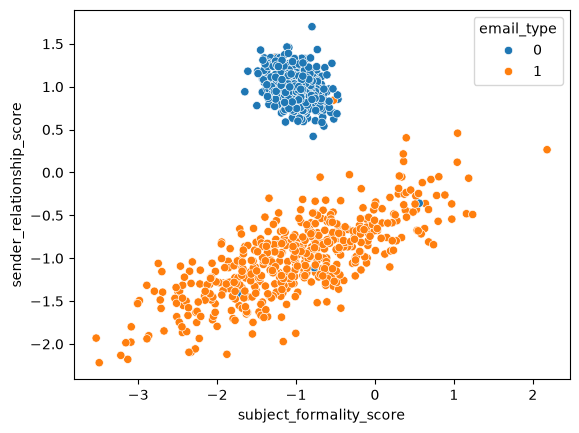

In [6]:
sns.scatterplot(x=df["subject_formality_score"],y=df["sender_relationship_score"],hue=df["email_type"])
plt.show()

In [7]:
X=df[["subject_formality_score","sender_relationship_score"]].values
y=df["email_type"].values

In [8]:
y

array([0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1, 1, 0, 0, 0, 1, 1, 0, 1,
       0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 0,
       0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 1, 1, 0, 1, 0, 1, 0, 0, 0,
       1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1,
       1, 1, 1, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 1, 1, 1, 1, 1, 1, 0, 1, 1,
       1, 0, 0, 1, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1,
       1, 1, 0, 0, 0, 1, 1, 0, 0, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 0, 1, 1,
       0, 0, 1, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0, 0, 1, 0, 1,
       1, 1, 1, 0, 1, 0, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 1,
       1, 0, 1, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1,
       1, 0, 0, 0, 0, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1,

In [9]:
X

array([[-1.49678965,  0.77925822],
       [-1.21760978,  0.88960104],
       [-0.37594518, -0.82332435],
       ...,
       [-1.36975007,  1.0222785 ],
       [-1.1850392 , -1.20266647],
       [-1.17835511,  1.08298346]], shape=(1000, 2))

In [10]:
from sklearn.model_selection import train_test_split

In [11]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [12]:
X_train

array([[-1.0117876 ,  1.23752419],
       [-0.17371594, -0.18965732],
       [-0.99900752,  0.96688407],
       ...,
       [-0.9629973 ,  1.26387822],
       [-1.20901347,  1.03434201],
       [-0.99495526,  1.09671733]], shape=(800, 2))

In [13]:
X_train=torch.tensor(X_train,dtype=torch.float32)
X_test=torch.tensor(X_test,dtype=torch.float32)

y_train=torch.tensor(y_train,dtype=torch.float32).unsqueeze(1)
y_test=torch.tensor(y_test,dtype=torch.float32).unsqueeze(1)

In [14]:
print(X_train.shape,y_train.shape)
print(X_test.shape,y_test.shape)

torch.Size([800, 2]) torch.Size([800, 1])
torch.Size([200, 2]) torch.Size([200, 1])


In [15]:
X_train.ndim

2

In [16]:
y_train.ndim

2

In [17]:
from torch import nn

In [18]:
class ClassificationModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1=nn.Linear(in_features=2,out_features=5)
        self.layer2=nn.Linear(in_features=5,out_features=1)
    def forward(self,x:torch.Tensor)->torch.Tensor:
        return self.layer2(self.layer1(x))

In [19]:
torch.manual_seed(42)
model0=ClassificationModel()

In [20]:
loss_fn=nn.BCEWithLogitsLoss()
optimizer= torch.optim.SGD(params=model0.parameters(),lr=0.01)

In [21]:
def calculate_accurarcy(y_test,y_pred):
    correct=torch.eq(y_test,y_pred).sum().item()
    accuracy=correct/len(y_pred)*100
    return accuracy

In [22]:
y_logits=model0(X_test)[:5]

In [23]:
y_logits

tensor([[-0.1342],
        [-0.2908],
        [-0.1631],
        [-0.2298],
        [-0.1364]], grad_fn=<SliceBackward0>)

In [24]:
y_pred_probs=torch.sigmoid(y_logits)

In [25]:
y_pred_probs

tensor([[0.4665],
        [0.4278],
        [0.4593],
        [0.4428],
        [0.4660]], grad_fn=<SigmoidBackward0>)

In [26]:
y_preds=torch.round(y_pred_probs)

In [27]:
y_preds

tensor([[0.],
        [0.],
        [0.],
        [0.],
        [0.]], grad_fn=<RoundBackward0>)

In [28]:
calculate_accurarcy(y_test[:5],y_preds)

60.0

In [29]:
epochs=500

for epoch in range(epochs):
   
    model0.train()
    
    y_logits=model0(X_train)
    y_pred=torch.round(torch.sigmoid(y_logits))
    
    loss=loss_fn(y_logits,y_train)
    acc=calculate_accurarcy(y_test=y_train,y_pred=y_pred)
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    model0.eval()

    with torch.inference_mode():
        test_logits=model0(X_test)
        test_pred=torch.round(torch.sigmoid(test_logits))
        test_loss=loss_fn(test_logits,y_test)
        test_acc=calculate_accurarcy(y_test=y_test,y_pred=test_pred)
    if epoch % 5==0:
        print(f"Epoch:{epoch},Train loss:{loss},Train accuracy:{acc},Test loss:{test_loss},Test Acc:{test_acc}")

Epoch:0,Train loss:0.723492443561554,Train accuracy:49.75,Test loss:0.7176529765129089,Test Acc:52.0
Epoch:5,Train loss:0.7069980502128601,Train accuracy:49.75,Test loss:0.7006773352622986,Test Acc:52.0
Epoch:10,Train loss:0.6911811232566833,Train accuracy:49.75,Test loss:0.6843975186347961,Test Acc:52.0
Epoch:15,Train loss:0.6759693622589111,Train accuracy:49.75,Test loss:0.6687402129173279,Test Acc:52.0
Epoch:20,Train loss:0.6612993478775024,Train accuracy:49.75,Test loss:0.6536413431167603,Test Acc:52.0
Epoch:25,Train loss:0.6471153497695923,Train accuracy:49.75,Test loss:0.6390445232391357,Test Acc:52.0
Epoch:30,Train loss:0.6333684325218201,Train accuracy:50.125,Test loss:0.6249003410339355,Test Acc:52.0
Epoch:35,Train loss:0.6200160384178162,Train accuracy:52.625,Test loss:0.6111659407615662,Test Acc:54.0
Epoch:40,Train loss:0.6070208549499512,Train accuracy:58.62500000000001,Test loss:0.5978038311004639,Test Acc:63.5
Epoch:45,Train loss:0.5943505764007568,Train accuracy:64.5,Tes

In [30]:
import numpy as np
def plot_linear_decision_boundary(model, X, y):

    # layer_1: (5,2)
    # layer_2: (1,5)
    # toplam efektif ağırlık = layer_2.weight @ layer_1.weight = (1,2)
    W1 = model.layer1.weight.detach().numpy()       # shape (5,2)
    b1 = model.layer1.bias.detach().numpy()         # shape (5,)
    W2 = model.layer2.weight.detach().numpy()       # shape (1,5)
    b2 = model.layer2.bias.detach().numpy()[0]      # shape (1,)

    # efektif W ve b
    # W_eff = W2 * W1
    W_eff = W2 @ W1   # shape (1,2)
    w1, w2 = W_eff[0] # iki feature'ın ağırlığı

    # efektif b = W2 * b1 + b2
    b_eff = (W2 @ b1)[0] + b2

    # X aralığı
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    xs = np.linspace(x_min, x_max, 200)

    # Doğru denkleminden x2 hesaplama
    # w1*x1 + w2*x2 + b = 0  →  x2 = -(w1*x1 + b) / w2
    ys = -(w1 * xs + b_eff) / w2

    # Noktalar
    plt.scatter(X[:, 0], X[:, 1], c=y.squeeze(), cmap=plt.cm.RdYlBu, s=40)
    plt.plot(xs, ys, "k-", linewidth=3)
    plt.xlabel("subject_formality_score")
    plt.ylabel("sender_relationship_score")
    plt.xlim(x_min, x_max)
    plt.ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)

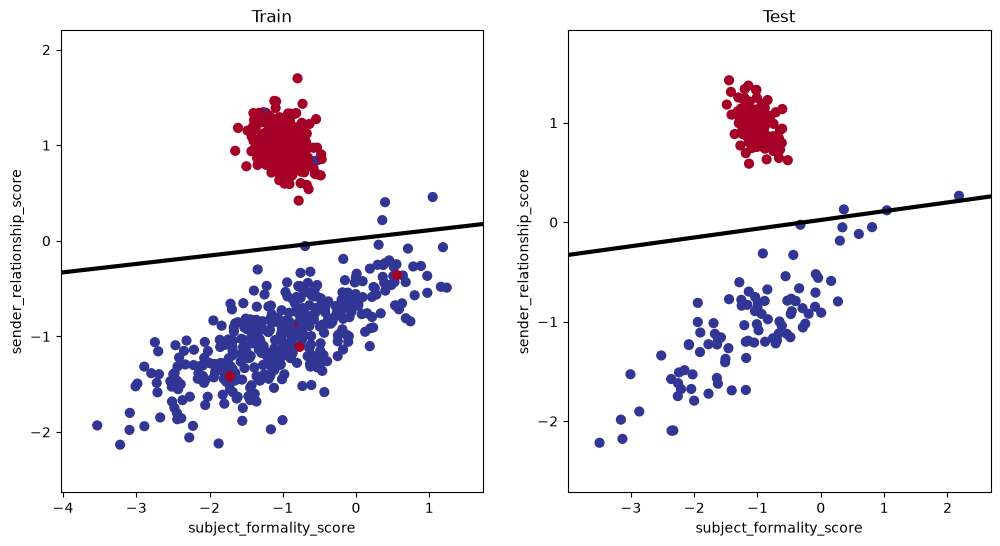

In [31]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.title("Train")
plot_linear_decision_boundary(model0, X_train, y_train)

plt.subplot(1, 2, 2)
plt.title("Test")
plot_linear_decision_boundary(model0, X_test, y_test)

plt.show()

In [32]:
df=pd.read_csv("08-seismic_activity_svm.csv")

In [33]:
df.head()

,underground_wave_energy,vibration_axis_variation,seismic_event_detected
0,9.539392,-3.000000,0
1,9.558241,-2.939394,0
2,9.576669,-2.878788,0
3,9.594678,-2.818182,0
4,9.612272,-2.757576,0


In [34]:
df.describe()

,underground_wave_energy,vibration_axis_variation,seismic_event_detected
count,400.000000,4.000000e+02,400.000000
mean,0.000000,8.881784e-18,0.500000
std,7.719350,1.751650e+00,0.500626
min,-9.999954,-3.000000e+00,0.000000
25%,-6.134779,-1.500000e+00,0.000000
50%,0.000000,0.000000e+00,0.500000
75%,6.134779,1.500000e+00,1.000000
max,9.999954,3.000000e+00,1.000000


In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   underground_wave_energy   400 non-null    float64
 1   vibration_axis_variation  400 non-null    float64
 2   seismic_event_detected    400 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 9.5 KB


In [36]:
df["seismic_event_detected"].unique()

array([0, 1])

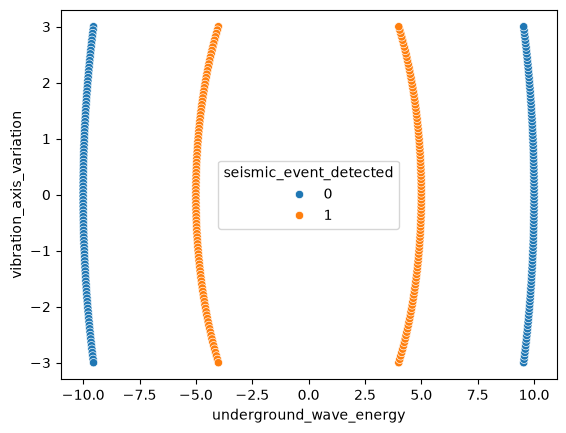

In [37]:
sns.scatterplot(x="underground_wave_energy",y="vibration_axis_variation",hue="seismic_event_detected",data=df)
plt.show()

In [38]:
X=df[["underground_wave_energy","vibration_axis_variation"]].values
y=df["seismic_event_detected"].values

In [39]:
X

array([[ 9.53939201, -3.        ],
       [ 9.55824059, -2.93939394],
       [ 9.57666854, -2.87878788],
       [ 9.59467828, -2.81818182],
       [ 9.61227215, -2.75757576],
       [ 9.62945245, -2.6969697 ],
       [ 9.64622137, -2.63636364],
       [ 9.66258107, -2.57575758],
       [ 9.67853361, -2.51515152],
       [ 9.69408101, -2.45454545],
       [ 9.70922521, -2.39393939],
       [ 9.7239681 , -2.33333333],
       [ 9.73831149, -2.27272727],
       [ 9.75225716, -2.21212121],
       [ 9.76580681, -2.15151515],
       [ 9.77896207, -2.09090909],
       [ 9.79172455, -2.03030303],
       [ 9.80409577, -1.96969697],
       [ 9.81607722, -1.90909091],
       [ 9.82767031, -1.84848485],
       [ 9.83887643, -1.78787879],
       [ 9.8496969 , -1.72727273],
       [ 9.86013297, -1.66666667],
       [ 9.87018588, -1.60606061],
       [ 9.87985679, -1.54545455],
       [ 9.88914683, -1.48484848],
       [ 9.89805706, -1.42424242],
       [ 9.90658851, -1.36363636],
       [ 9.91474216,

In [40]:
from sklearn.model_selection import train_test_split

In [41]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [42]:
X_train=torch.tensor(X_train,dtype=torch.float32)
X_test=torch.tensor(X_test,dtype=torch.float32)

y_train=torch.tensor(y_train,dtype=torch.float32).unsqueeze(1)
y_test=torch.tensor(y_test,dtype=torch.float32).unsqueeze(1)

In [43]:
print(X_train.shape,y_train.shape)
print(X_test.shape,y_test.shape)

torch.Size([320, 2]) torch.Size([320, 1])
torch.Size([80, 2]) torch.Size([80, 1])


In [44]:
X_train.ndim

2

In [45]:
y_train.ndim

2

In [46]:
from torch import nn

In [47]:
class ClassifactionModel1(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1=nn.Linear(in_features=2,out_features=8)
        self.layer2=nn.Linear(in_features=8,out_features=1)
    def forward(self,x:torch.Tensor)->torch.Tensor:
        return self.layer2(self.layer1(x))

In [48]:
torch.manual_seed(42)
model=ClassifactionModel1()
loss_fn=nn.BCEWithLogitsLoss()
optimizier=torch.optim.SGD(params=model.parameters(),lr=0.01)

In [49]:
def calculate_accuary1(y_test,y_pred):
    correct=torch.eq(y_test,y_pred).sum().item()
    accuary=correct/len(y_train)*100
    return accuary

In [50]:
epochs=500
for epoch in range(epochs):
    model.train()
    
    y_logits=model(X_train)
    y_pred=torch.round(torch.sigmoid(y_logits))

    loss=loss_fn(y_logits,y_train)
    acc=calculate_accuary1(y_test=y_train,y_pred=y_pred)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    with torch.inference_mode():
        test_logit=model(X_test)
        test_pred=torch.round(torch.sigmoid(test_logit))

        test_loss=loss_fn(test_logit,y_test)
        test_acc=calculate_accuary1(y_test=y_test,y_pred=test_pred)
    if epoch % 50==0:
        print(f"Epoch:{epoch}\n Train loss:{loss}\n Train Acc:{acc} \n Test loss:{test_loss}\n Test Acc:{test_acc} ")

Epoch:0
 Train loss:0.9493039846420288
 Train Acc:45.9375 
 Test loss:0.7917426824569702
 Test Acc:14.0625 
Epoch:50
 Train loss:0.9493039846420288
 Train Acc:45.9375 
 Test loss:0.7917426824569702
 Test Acc:14.0625 
Epoch:100
 Train loss:0.9493039846420288
 Train Acc:45.9375 
 Test loss:0.7917426824569702
 Test Acc:14.0625 
Epoch:150
 Train loss:0.9493039846420288
 Train Acc:45.9375 
 Test loss:0.7917426824569702
 Test Acc:14.0625 
Epoch:200
 Train loss:0.9493039846420288
 Train Acc:45.9375 
 Test loss:0.7917426824569702
 Test Acc:14.0625 
Epoch:250
 Train loss:0.9493039846420288
 Train Acc:45.9375 
 Test loss:0.7917426824569702
 Test Acc:14.0625 
Epoch:300
 Train loss:0.9493039846420288
 Train Acc:45.9375 
 Test loss:0.7917426824569702
 Test Acc:14.0625 
Epoch:350
 Train loss:0.9493039846420288
 Train Acc:45.9375 
 Test loss:0.7917426824569702
 Test Acc:14.0625 
Epoch:400
 Train loss:0.9493039846420288
 Train Acc:45.9375 
 Test loss:0.7917426824569702
 Test Acc:14.0625 
Epoch:450
 Tr

In [51]:
import numpy as np
def plot_linear_decision_boundary(model, X, y):

    # layer_1: (5,2)
    # layer_2: (1,5)
    # toplam efektif ağırlık = layer_2.weight @ layer_1.weight = (1,2)
    W1 = model.layer1.weight.detach().numpy()       # shape (5,2)
    b1 = model.layer1.bias.detach().numpy()         # shape (5,)
    W2 = model.layer2.weight.detach().numpy()       # shape (1,5)
    b2 = model.layer2.bias.detach().numpy()[0]      # shape (1,)

    # efektif W ve b
    # W_eff = W2 * W1
    W_eff = W2 @ W1   # shape (1,2)
    w1, w2 = W_eff[0] # iki feature'ın ağırlığı

    # efektif b = W2 * b1 + b2
    b_eff = (W2 @ b1)[0] + b2

    # X aralığı
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    xs = np.linspace(x_min, x_max, 200)

    # Doğru denkleminden x2 hesaplama
    # w1*x1 + w2*x2 + b = 0  →  x2 = -(w1*x1 + b) / w2
    ys = -(w1 * xs + b_eff) / w2

    # Noktalar
    plt.scatter(X[:, 0], X[:, 1], c=y.squeeze(), cmap=plt.cm.RdYlBu, s=40)
    plt.plot(xs, ys, "k-", linewidth=3)
    plt.xlabel("subject_formality_score")
    plt.ylabel("sender_relationship_score")
    plt.xlim(x_min, x_max)
    plt.ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)

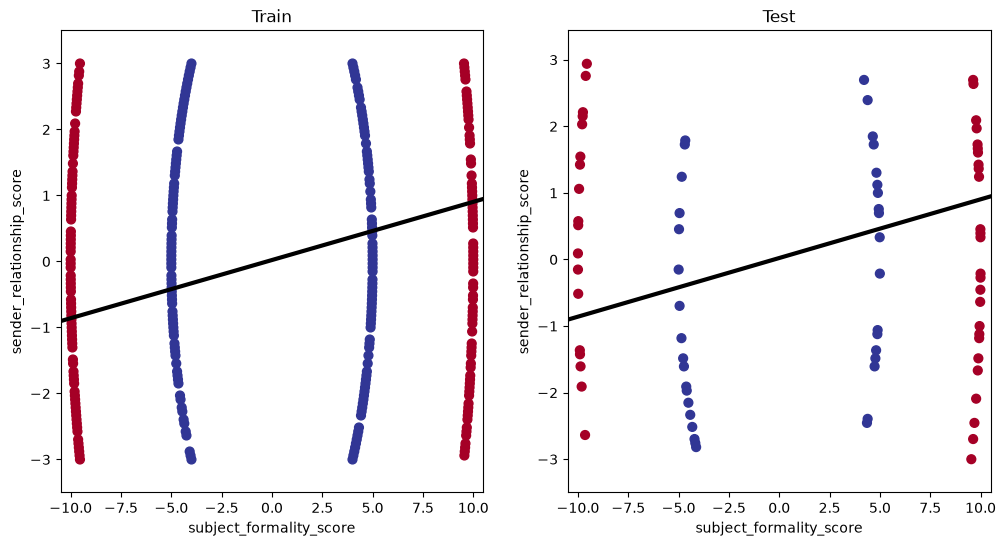

In [52]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.title("Train")
plot_linear_decision_boundary(model0, X_train, y_train)

plt.subplot(1, 2, 2)
plt.title("Test")
plot_linear_decision_boundary(model0, X_test, y_test)

plt.show()

In [53]:
class ReLuModel(nn.Module):
    def __init__(self):
        super().__init__()
    
        self.layer1=nn.Linear(in_features=2,out_features=8)
        self.relu=nn.ReLU()
        self.layer2=nn.Linear(in_features=8,out_features=1)
    
    def forward(self,x:torch.Tensor)->torch.Tensor:
        return self.layer2(self.relu(self.layer1(x)))

In [54]:
torch.manual_seed(42)
relu_model=ReLuModel()
loss_fn=nn.BCEWithLogitsLoss()
optimizer=torch.optim.SGD(params=relu_model.parameters(),lr=0.01)

In [55]:
def calculate_accuarcy(y_test,y_pred):
    correct=torch.eq(y_test,y_pred).sum().item()
    accuarcy=correct/len(y_pred)*100
    return accuarcy

In [56]:
epochs=500
for epoch in range (epochs):
    relu_model.train()

    y_logits=relu_model(X_train)
    y_pred=torch.round(torch.sigmoid(y_logits))

    loss=loss_fn(y_logits,y_train)
    acc=calculate_accuarcy(y_test=y_train,y_pred=y_pred)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    with torch.inference_mode():
        test_logits=relu_model(X_test)
        test_pred=torch.round(torch.sigmoid(test_logits))

        test_loss=loss_fn(test_logits,y_test)
        test_acc=calculate_accuarcy(y_test=y_test,y_pred=test_pred) 
    if epoch % 50==0:
        print(f"Epoch:{epoch}\n Train loss:{loss}\n Train Acc:{acc} \n Test loss:{test_loss}\n Test Acc:{test_acc} ")

Epoch:0
 Train loss:0.762305498123169
 Train Acc:53.75 
 Test loss:0.63416588306427
 Test Acc:66.25 
Epoch:50
 Train loss:0.6299018859863281
 Train Acc:56.875 
 Test loss:0.5694952607154846
 Test Acc:68.75 
Epoch:100
 Train loss:0.6109629273414612
 Train Acc:56.56250000000001 
 Test loss:0.5553468465805054
 Test Acc:68.75 
Epoch:150
 Train loss:0.5945925116539001
 Train Acc:56.25 
 Test loss:0.5419172644615173
 Test Acc:68.75 
Epoch:200
 Train loss:0.5794838666915894
 Train Acc:56.25 
 Test loss:0.5292847752571106
 Test Acc:68.75 
Epoch:250
 Train loss:0.5651401281356812
 Train Acc:56.56250000000001 
 Test loss:0.5174049735069275
 Test Acc:68.75 
Epoch:300
 Train loss:0.551322340965271
 Train Acc:56.875 
 Test loss:0.5061746835708618
 Test Acc:68.75 
Epoch:350
 Train loss:0.5378859639167786
 Train Acc:59.06249999999999 
 Test loss:0.4954814910888672
 Test Acc:70.0 
Epoch:400
 Train loss:0.5247283577919006
 Train Acc:62.81250000000001 
 Test loss:0.4852115213871002
 Test Acc:72.5 
Epoch

In [60]:
import torch
import numpy as np
import matplotlib.pyplot as plt

def plot_decision_boundary(model, X, y):

    model.eval()

    # Tensorları NumPy dizisine çevir
    X_np = X.detach().cpu().numpy()
    y_np = y.detach().cpu().numpy().reshape(-1)

    # Grafiğin sınırları
    x_min, x_max = X_np[:, 0].min() - 0.5, X_np[:, 0].max() + 0.5
    y_min, y_max = X_np[:, 1].min() - 0.5, X_np[:, 1].max() + 0.5

    # Nokta ızgarası oluştur
    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 200),
        np.linspace(y_min, y_max, 200)
    )

    # Tüm noktaları modele gönder
    grid = np.c_[xx.ravel(), yy.ravel()]

    grid_tensor = torch.tensor(
        grid,
        dtype=X.dtype,
        device=next(model.parameters()).device
    )

    with torch.inference_mode():
        logits = model(grid_tensor)
        probs = torch.sigmoid(logits)
        predictions = probs.reshape(xx.shape).cpu().numpy()

    # Karar bölgelerini çiz
    plt.contourf(
        xx, yy, predictions,
        levels=[0, 0.5, 1],
        cmap=plt.cm.RdYlBu,
        alpha=0.4
    )

    # Karar sınırı
    plt.contour(
        xx, yy, predictions,
        levels=[0.5],
        colors="black",
        linewidths=2
    )

    # Gerçek veri noktaları
    plt.scatter(
        X_np[:, 0],
        X_np[:, 1],
        c=y_np,
        cmap=plt.cm.RdYlBu,
        edgecolors="black",
        s=40
    )

    plt.xlabel("subject_formality_score")
    plt.ylabel("sender_relationship_score")

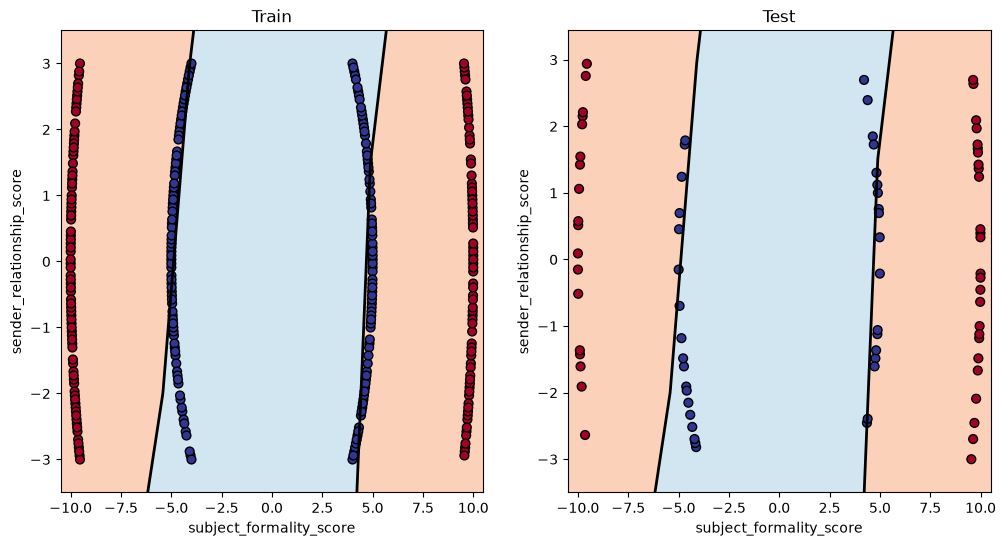

In [61]:
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.title("Train")
plot_decision_boundary(relu_model, X_train, y_train)

plt.subplot(1, 2, 2)
plt.title("Test")
plot_decision_boundary(relu_model, X_test, y_test)

plt.show()